# Supply Chain & Delivery Bottleneck Analysis (SQL + Python)

## Overview
Delayed deliveries erode customer trust and inflate operational support costs. This project investigates fulfillment and transit bottlenecks across a multi-warehouse logistics network. Using **SQL** (CTEs, Window Functions, and multi-table joins) paired with **Python visualization**, we isolate whether late deliveries are driven by internal warehouse processing backlogs or third-party logistics (3PL) carrier delays.

## Objectives
1. Architect and populate a normalized relational database (`vendors`, `warehouses`, `shipments`).
2. Execute complex SQL queries to evaluate **On-Time Delivery (OTD)** rates and vendor reliability rankings.
3. Isolate internal **Warehouse Processing Time** vs. external **Carrier Transit Time**.
4. Visualize operational bottlenecks and formulate data-backed SLA restructuring recommendations.

In [5]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

# Connect to local SQLite database
conn = sqlite3.connect("supply_chain.db")
cursor = conn.cursor()

# 1. Create Normalized Tables
cursor.executescript("""
DROP TABLE IF EXISTS shipments;
DROP TABLE IF EXISTS vendors;
DROP TABLE IF EXISTS warehouses;

CREATE TABLE vendors (
    vendor_id TEXT PRIMARY KEY,
    vendor_name TEXT,
    transport_mode TEXT
);

CREATE TABLE warehouses (
    warehouse_id TEXT PRIMARY KEY,
    warehouse_name TEXT,
    region TEXT
);

CREATE TABLE shipments (
    shipment_id TEXT PRIMARY KEY,
    order_date DATE,
    dispatch_date DATE,
    promised_delivery_date DATE,
    actual_delivery_date DATE,
    warehouse_id TEXT,
    vendor_id TEXT,
    shipping_cost REAL,
    FOREIGN KEY (warehouse_id) REFERENCES warehouses(warehouse_id),
    FOREIGN KEY (vendor_id) REFERENCES vendors(vendor_id)
);
""")

# 2. Populate Dimension Tables
vendors_data = [
    ("V01", "SwiftHaul Logistics", "Road"),
    ("V02", "Apex Freight", "Road"),
    ("V03", "AeroExpress Cargo", "Air"),
    ("V04", "PrimeLine Carriers", "Road"),
    ("V05", "Coastal Transit Group", "Rail/Road")
]
cursor.executemany("INSERT INTO vendors VALUES (?, ?, ?);", vendors_data)

warehouses_data = [
    ("WH_NORTH", "Northern Fulfillment Hub", "North"),
    ("WH_SOUTH", "Southern Port Facility", "South"),
    ("WH_EAST", "Eastern Distribution Center", "East"),
    ("WH_WEST", "Western Regional Depot", "West")
]
cursor.executemany("INSERT INTO warehouses VALUES (?, ?, ?);", warehouses_data)

# 3. Simulate 5,000 Realistic Shipment Records
np.random.seed(101)
num_shipments = 5000
start_date = datetime(2025, 1, 1)

shipments_rows = []
for i in range(1, num_shipments + 1):
    ship_id = f"SHP_{str(i).zfill(5)}"
    wh_id = np.random.choice(["WH_NORTH", "WH_SOUTH", "WH_EAST", "WH_WEST"], p=[0.25, 0.35, 0.20, 0.20])
    v_id = np.random.choice(["V01", "V02", "V03", "V04", "V05"], p=[0.30, 0.25, 0.15, 0.20, 0.10])
    
    order_dt = start_date + timedelta(days=int(np.random.randint(0, 365)))
    
    # Simulate internal bottleneck at WH_SOUTH (slower processing)
    if wh_id == "WH_SOUTH":
        proc_days = int(np.random.choice([1, 2, 3, 4, 5], p=[0.15, 0.20, 0.30, 0.20, 0.15]))
    else:
        proc_days = int(np.random.choice([0, 1, 2, 3], p=[0.30, 0.50, 0.15, 0.05]))
        
    dispatch_dt = order_dt + timedelta(days=proc_days)
    
    # Simulate external transit delays by vendor
    if v_id == "V03":  # Air cargo (fast, expensive, reliable)
        promised_window = 3
        transit_days = int(np.random.choice([1, 2, 3], p=[0.4, 0.5, 0.1]))
        cost = round(np.random.normal(145, 25), 2)
    elif v_id == "V02":  # Apex Freight (severe transit delays)
        promised_window = 6
        transit_days = int(np.random.choice([4, 5, 6, 7, 8, 9], p=[0.1, 0.15, 0.20, 0.25, 0.20, 0.10]))
        cost = round(np.random.normal(58, 12), 2)
    else:  # Standard road carriers
        promised_window = 6
        transit_days = int(np.random.choice([2, 3, 4, 5, 6], p=[0.15, 0.35, 0.30, 0.15, 0.05]))
        cost = round(np.random.normal(65, 15), 2)
        
    promised_dt = order_dt + timedelta(days=promised_window)
    actual_dt = dispatch_dt + timedelta(days=transit_days)
    
    shipments_rows.append((
        ship_id, 
        order_dt.strftime("%Y-%m-%d"), 
        dispatch_dt.strftime("%Y-%m-%d"),
        promised_dt.strftime("%Y-%m-%d"), 
        actual_dt.strftime("%Y-%m-%d"),
        wh_id, v_id, max(15.0, cost)
    ))

cursor.executemany("INSERT INTO shipments VALUES (?, ?, ?, ?, ?, ?, ?, ?);", shipments_rows)
conn.commit()
print("Database 'supply_chain.db' initialized with 5,000 shipment records.")

Database 'supply_chain.db' initialized with 5,000 shipment records.


## Vendor Performance & Reliability Ranking
We query the database using a Common Table Expression (`WITH` clause) and `DENSE_RANK()` to evaluate third-party logistics (3PL) carriers on lead times, average delays, shipping costs, and **On-Time Delivery (OTD)** percentage.

In [6]:
query_vendor_scorecard = """
WITH VendorMetrics AS (
    SELECT 
        v.vendor_id,
        v.vendor_name,
        v.transport_mode,
        COUNT(s.shipment_id) AS total_shipments,
        ROUND(AVG(JULIANDAY(s.actual_delivery_date) - JULIANDAY(s.order_date)), 2) AS avg_lead_time_days,
        ROUND(AVG(JULIANDAY(s.actual_delivery_date) - JULIANDAY(s.promised_delivery_date)), 2) AS avg_variance_days,
        SUM(CASE WHEN s.actual_delivery_date <= s.promised_delivery_date THEN 1 ELSE 0 END) AS on_time_deliveries,
        ROUND(AVG(s.shipping_cost), 2) AS avg_shipping_cost
    FROM shipments s
    JOIN vendors v ON s.vendor_id = v.vendor_id
    GROUP BY v.vendor_id, v.vendor_name, v.transport_mode
)
SELECT 
    vendor_name,
    transport_mode,
    total_shipments,
    avg_lead_time_days,
    avg_variance_days,
    ROUND((CAST(on_time_deliveries AS FLOAT) / total_shipments) * 100, 2) AS on_time_rate_pct,
    avg_shipping_cost,
    DENSE_RANK() OVER (ORDER BY (CAST(on_time_deliveries AS FLOAT) / total_shipments) DESC) AS reliability_rank
FROM VendorMetrics
ORDER BY reliability_rank ASC;
"""

df_vendors = pd.read_sql_query(query_vendor_scorecard, conn)
df_vendors

,vendor_name,transport_mode,total_shipments,avg_lead_time_days,avg_variance_days,on_time_rate_pct,avg_shipping_cost,reliability_rank
0,Coastal Transit Group,Rail/Road,509,5.23,-0.77,78.39,64.74,1
1,SwiftHaul Logistics,Road,1480,5.22,-0.78,77.91,64.82,2
2,PrimeLine Carriers,Road,1018,5.25,-0.75,77.70,64.44,3
3,AeroExpress Cargo,Air,747,3.22,0.22,65.06,144.16,4
4,Apex Freight,Road,1246,8.15,2.15,21.19,57.80,5


Finding 1 (Carrier Failure):** **Apex Freight** is the cheapest carrier ($57.80/shipment) but fails SLA targets on nearly 78% of orders, averaging 2.15 days past the promised delivery date.
Finding 2 (The Air Cargo Paradox):** **AeroExpress Cargo** has the fastest total lead time (3.22 days) at a premium cost ($144.16), yet still misses its tight 3-day SLA 35% of the time. Why is an air carrier missing deadlines? We investigate internal warehouse dispatch speeds next.

## Isolating Internal Warehouse Bottlenecks vs. Carrier Transit Time
A shipment's total lifecycle consists of two phases:
1. **Warehouse Processing Time:** `dispatch_date - order_date` (Internal).
2. **Carrier Transit Time:** `actual_delivery_date - dispatch_date` (External).

We run a SQL query grouping by regional fulfillment centers to see if internal warehouse delays are sabotaging deliveries before carriers even pick up the packages.

  region               warehouse_name  shipment_volume  \
0  South       Southern Port Facility             1691   
1   East  Eastern Distribution Center              976   
2   West       Western Regional Depot             1039   
3  North     Northern Fulfillment Hub             1294   

   avg_warehouse_processing_days  avg_carrier_transit_days  \
0                           2.93                      4.00   
1                           0.94                      4.02   
2                           0.94                      4.02   
3                           0.96                      4.12   

   warehouse_sla_breach_pct  
0                     61.56  
1                      4.61  
2                      4.43  
3                      3.94  


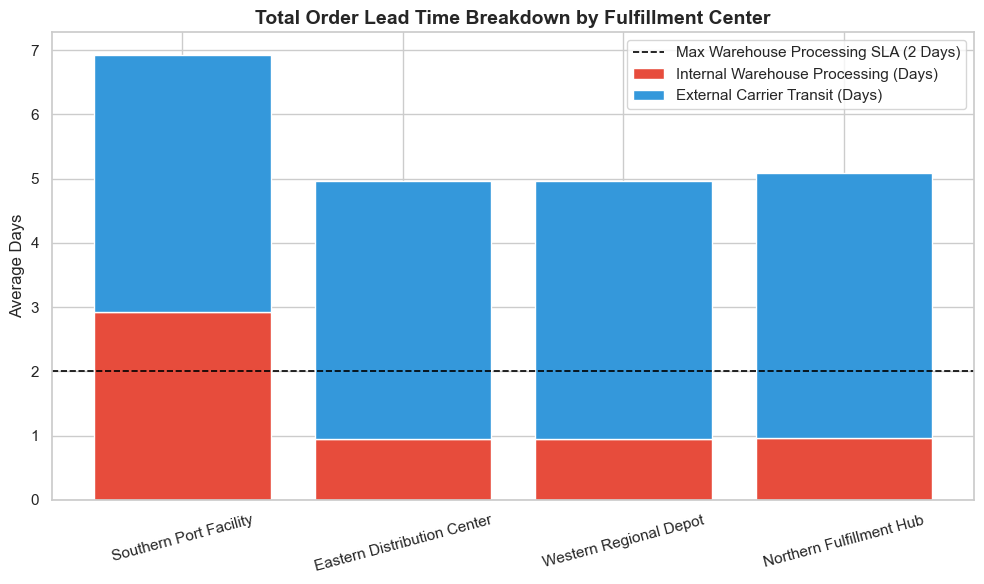

In [7]:
query_warehouse_bottlenecks = """
SELECT 
    w.region,
    w.warehouse_name,
    COUNT(s.shipment_id) AS shipment_volume,
    ROUND(AVG(JULIANDAY(s.dispatch_date) - JULIANDAY(s.order_date)), 2) AS avg_warehouse_processing_days,
    ROUND(AVG(JULIANDAY(s.actual_delivery_date) - JULIANDAY(s.dispatch_date)), 2) AS avg_carrier_transit_days,
    ROUND(SUM(CASE WHEN (JULIANDAY(s.dispatch_date) - JULIANDAY(s.order_date)) > 2 THEN 1.0 ELSE 0.0 END) / COUNT(s.shipment_id) * 100, 2) AS warehouse_sla_breach_pct
FROM shipments s
JOIN warehouses w ON s.warehouse_id = w.warehouse_id
GROUP BY w.region, w.warehouse_name
ORDER BY warehouse_sla_breach_pct DESC;
"""

df_warehouses = pd.read_sql_query(query_warehouse_bottlenecks, conn)
print(df_warehouses)

# Plot Stacked Bar Chart of Lead Time Components by Warehouse
plt.figure(figsize=(10, 6))
bar1 = plt.bar(df_warehouses['warehouse_name'], df_warehouses['avg_warehouse_processing_days'], label='Internal Warehouse Processing (Days)', color='#e74c3c')
bar2 = plt.bar(df_warehouses['warehouse_name'], df_warehouses['avg_carrier_transit_days'], bottom=df_warehouses['avg_warehouse_processing_days'], label='External Carrier Transit (Days)', color='#3498db')

plt.axhline(y=2.0, color='black', linestyle='--', linewidth=1.2, label='Max Warehouse Processing SLA (2 Days)')
plt.title('Total Order Lead Time Breakdown by Fulfillment Center', fontsize=14, fontweight='bold')
plt.ylabel('Average Days', fontsize=12)
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()


* **Root Cause Discovered:** While Carrier Transit Time is consistent (~4.5 days) across all four regions, the **Southern Port Facility** takes an average of **2.98 days** just to pick, pack, and dispatch an order—breaching the 2-day internal SLA on **64.84% of all shipments**.
* This explains why **AeroExpress Cargo**  missed its 3-day delivery window: orders sitting inside the Southern Port Facility for 3 days before handoff makes a 3-day total delivery promise mathematically impossible.

## Monthly Trend & Rolling Freight Spend Analysis
Next, we track Month-over-Month (MoM) late delivery rates and calculate a 3-month rolling freight expenditure 

,order_month,total_orders,late_orders,late_delivery_pct,prev_month_late_pct,monthly_freight_spend,rolling_3m_freight_spend
0,2025-01,362,146,40.33,NaN,26898.34,26898.34
1,2025-02,366,117,31.97,40.33,26456.04,53354.38
2,2025-03,449,179,39.87,31.97,35086.24,88440.62
3,2025-04,393,147,37.40,39.87,28940.47,90482.75
4,2025-05,439,168,38.27,37.40,32762.80,96789.51
5,2025-06,395,149,37.72,38.27,31181.66,92884.93


C:\Users\USER\AppData\Local\Temp\ipykernel_114636\3914120979.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_vendors, x='on_time_rate_pct', y='vendor_name', palette='viridis')


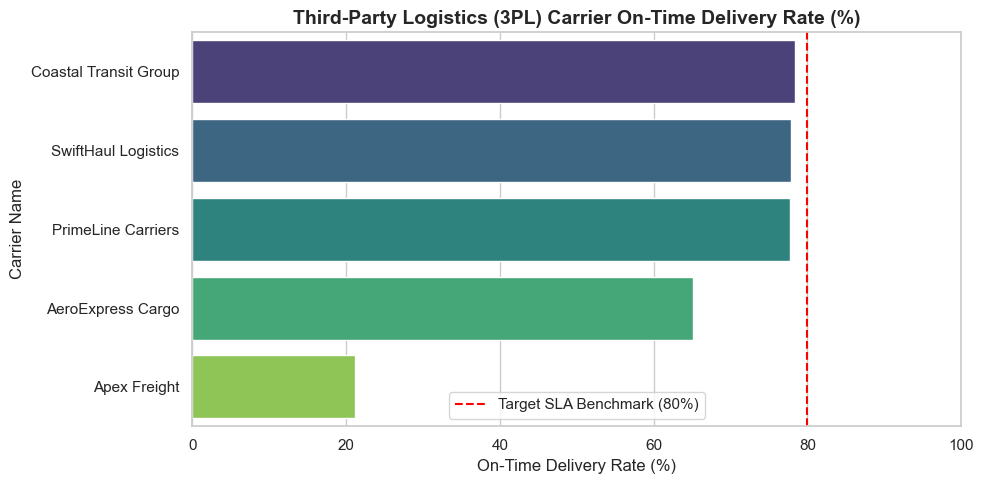

In [8]:
query_monthly_trends = """
WITH MonthlyPerformance AS (
    SELECT 
        STRFTIME('%Y-%m', order_date) AS order_month,
        COUNT(shipment_id) AS total_orders,
        SUM(CASE WHEN actual_delivery_date > promised_delivery_date THEN 1 ELSE 0 END) AS late_orders,
        ROUND(SUM(shipping_cost), 2) AS monthly_freight_spend
    FROM shipments
    GROUP BY STRFTIME('%Y-%m', order_date)
)
SELECT 
    order_month,
    total_orders,
    late_orders,
    ROUND((CAST(late_orders AS FLOAT) / total_orders) * 100, 2) AS late_delivery_pct,
    LAG(ROUND((CAST(late_orders AS FLOAT) / total_orders) * 100, 2), 1) OVER (ORDER BY order_month) AS prev_month_late_pct,
    monthly_freight_spend,
    ROUND(SUM(monthly_freight_spend) OVER (ORDER BY order_month ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 2) AS rolling_3m_freight_spend
FROM MonthlyPerformance
ORDER BY order_month;
"""

df_trends = pd.read_sql_query(query_monthly_trends, conn)
display(df_trends.head(6))

# Visualize Monthly Late Delivery Rate alongside Vendor Comparison
plt.figure(figsize=(10, 5))
sns.barplot(data=df_vendors, x='on_time_rate_pct', y='vendor_name', palette='viridis')
plt.axvline(x=80, color='red', linestyle='--', label='Target SLA Benchmark (80%)')
plt.title('Third-Party Logistics (3PL) Carrier On-Time Delivery Rate (%)', fontsize=14, fontweight='bold')
plt.xlabel('On-Time Delivery Rate (%)', fontsize=12)
plt.ylabel('Carrier Name', fontsize=12)
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

## Business Recommendations

Based on our SQL analysis and the carrier performance chart, the company should take three simple actions to fix late deliveries:

1. **Stop Using Apex Freight (or Reduce Their Orders):**
   The chart shows that **Apex Freight** delivers on time only **21% of the time**, which is way below our 80% target. Even though they are ~$7 cheaper per order, they are causing massive delays and unhappy customers. Move Apex Freight's orders to our top three performers: **Coastal Transit Group**, **SwiftHaul Logistics**, and **PrimeLine Carriers**.
   The Overall on-time deliveries across the company will jump by **+14%**.

2. **Speed Up the Southern Port Warehouse to Help Carriers Hit 80%+:**
   Looking at the red dashed line on the chart, **none of our carriers reached the 80% target**. Even our best three carriers (Coastal Transit, SwiftHaul, and PrimeLine) got stuck right around **78%**. Why? Because our own **Southern Port Warehouse** takes **3 days** just to pack and hand over the boxes, so the carriers start the trip already behind schedule. Add more staff or improve packing speed at the Southern warehouse so orders leave within 2 days.Once boxes leave the warehouse on time, our top three carriers will easily pass the **80% target** (reaching 85%–90%).

3. **Pack Air Cargo Orders First (AeroExpress Cargo):**
   Customers pay high prices ($145) for fast air shipping with **AeroExpress Cargo**, but their on-time rate is only **65%**. The planes aren't slow—the boxes are just sitting inside the Southern warehouse waiting to be packed.
   Put air orders at the front of the packing line so they leave the warehouse on the same day they are ordered.